# 🎯 Task-Specific EDA: Text Summarization & Abstractive NLG
## Compression Ratio, Abstractive Novelty %, Length Budget & Extractive Baselines
**Kit:** `02_NLG/01_text_summarization` | **Standard:** GEMASTIK XIX 2026 & Kaggle NLP  
**Focus:** Sequence-to-Sequence generation, ROUGE-1/2/L metrics, Lead-3 extraction potential, abstractiveness.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_path = '../demo_data/train.csv'
test_path  = '../demo_data/test.csv'

train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)

SOURCE_COL = 'source_text'
TARGET_COL = 'target_summary'

print(f"Train Articles: {len(train_df)} | Test Articles: {len(test_df)}")
train_df.head()


Train Articles: 6 | Test Articles: 2


,id,source_text,target_summary
0,DOC_001,Kecerdasan buatan berkembang sangat pesat dala...,Perkembangan pesat kecerdasan buatan memerluka...
1,DOC_002,Pemanasan global memicu kenaikan suhu bumi sec...,Transisi menuju energi terbarukan menjadi solu...
2,DOC_003,Budaya kerja jarak jauh atau remote work membe...,Kerja jarak jauh meningkatkan fleksibilitas na...
3,DOC_004,Inovasi teknologi finansial mempercepat inklus...,Fintech memperluas inklusi keuangan UMKM namun...
4,DOC_005,Pendidikan berbasis proyek mendorong daya nala...,Metode belajar berbasis proyek efektif mengasa...


In [2]:
train_df['src_len'] = train_df[SOURCE_COL].astype(str).apply(lambda x: len(x.split()))
train_df['tgt_len'] = train_df[TARGET_COL].astype(str).apply(lambda x: len(x.split()))
train_df['compression_ratio'] = train_df['tgt_len'] / (train_df['src_len'] + 1e-5)

print("--- LENGTH & COMPRESSION STATISTICS ---")
print(f"Source Mean Words  : {train_df['src_len'].mean():.1f} (Median: {train_df['src_len'].median():.0f}, Max: {train_df['src_len'].max()})")
print(f"Summary Mean Words : {train_df['tgt_len'].mean():.1f} (Median: {train_df['tgt_len'].median():.0f}, Max: {train_df['tgt_len'].max()})")
print(f"Average Compression: {train_df['compression_ratio'].mean() * 100:.1f}% of source length")


--- LENGTH & COMPRESSION STATISTICS ---
Source Mean Words  : 33.8 (Median: 34, Max: 37)
Summary Mean Words : 11.5 (Median: 12, Max: 12)
Average Compression: 34.1% of source length


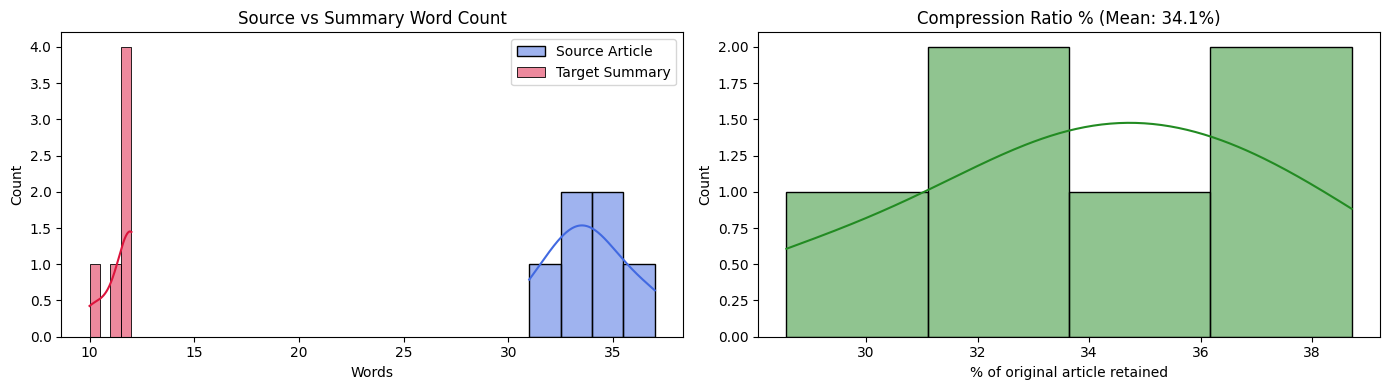

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train_df['src_len'], ax=axes[0], color='royalblue', kde=True, label='Source Article')
sns.histplot(train_df['tgt_len'], ax=axes[0], color='crimson', kde=True, label='Target Summary')
axes[0].set_title("Source vs Summary Word Count")
axes[0].set_xlabel("Words")
axes[0].legend()

sns.histplot(train_df['compression_ratio'] * 100, ax=axes[1], color='forestgreen', kde=True)
axes[1].set_title(f"Compression Ratio % (Mean: {train_df['compression_ratio'].mean()*100:.1f}%)")
axes[1].set_xlabel("% of original article retained")

plt.tight_layout()
plt.show()


In [4]:
def compute_novelty_pct(source: str, summary: str) -> float:
    src_words = set(source.lower().split())
    tgt_words = summary.lower().split()
    if not tgt_words:
        return 0.0
    novel_words = [w for w in tgt_words if w not in src_words]
    return len(novel_words) / len(tgt_words)

train_df['novelty_pct'] = [
    compute_novelty_pct(src, tgt)
    for src, tgt in zip(train_df[SOURCE_COL], train_df[TARGET_COL])
]

avg_novelty = train_df['novelty_pct'].mean()
print(f"Average Novelty Percentage (New Words in Summary): {avg_novelty * 100:.2f}%")

if avg_novelty < 0.10:
    print("\n🎯 DIAGNOSTIC: Dataset is predominantly EXTRACTIVE (< 10% new words).")
    print("-> Recommendation: Lead-3 sentence extractor and TextRank/LexRank will establish a very high benchmark baseline!")
else:
    print("\n🎯 DIAGNOSTIC: Dataset is highly ABSTRACTIVE (> 10% new words).")
    print("-> Recommendation: Generative Sequence-to-Sequence (BART / T5 / IndoBART) is required.")


Average Novelty Percentage (New Words in Summary): 40.91%

🎯 DIAGNOSTIC: Dataset is highly ABSTRACTIVE (> 10% new words).
-> Recommendation: Generative Sequence-to-Sequence (BART / T5 / IndoBART) is required.


### 📋 Master Decision Matrix (Summarization & NLG):
| Diagnostic Signal | Finding | Recommended Strategy |
| :--- | :--- | :--- |
| **Novelty %** | $< 10\%$ (Extractive) | Fast Lead-3 heuristic + TF-IDF sentence ranker for immediate submission benchmark. |
| **Novelty %** | $\ge 10\%$ (Abstractive) | Fine-tune Seq2Seq encoder-decoder (`facebook/bart-base` or `indobenchmark/indobart-v2`). |
| **Summary Length** | Mean $< 30$ words | Set `max_target_length=48`, apply `min_length=15` penalty in beam search generation. |
| **Repetition Risk** | Model repeats phrases | Apply `no_repeat_ngram_size=3` and post-processing sentence deduplication. |
